In [ ]:
import re
from timeit import timeit

import numpy as np
import pandas as pd
import optuna
import optuna_integration

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, f1_score, roc_curve, RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve, auc
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

import xgboost as xgb

SEED = 1

In [58]:
pd.set_option("display.max_columns", None)
sns.set(rc={"figure.figsize": (13, 7)})

# Data preparation and analysis

### Data loading

In [59]:
df = pd.read_csv("ctr_task_dataset.csv", sep="\t", index_col=0)
df["ts"] = pd.to_datetime(df.ts)
df.head()

,ts,exchange_id,dimension_id,rtb_url,ab_fold,ias_viewability,google_ctr,google_viewability,bid_value,user_agent,ip,device_type,biz,connection_type,country,region,city,metro,latitude,longitude,postal_code,is_clicked
0,2024-04-13 09:27:46,14,250,https://coordisnap.com/c/710534/5,a,65.0,NaN,NaN,78.0,Mozilla/5.0 (Linux; Android 13; SC-51B Build/T...,4ba73be5df4c59201e30279ed78b9c67,1,business,mobile wireless,jp,13,suginami,NaN,35.69242,139.63786,166-0015,1
1,2024-04-13 05:30:07,2,250,magicplaystudio.club,a,85.0,NaN,NaN,27.0,Mozilla/5.0 (Linux; Android 12; Lenovo TB-J607...,64136336256d85d724a098b8325fc39d,2,business,cable,jp,30,shingu,NaN,33.68545,135.98235,647-0061,1
2,2024-03-19 03:10:51,2,890689,https://www.lettuceclub.net/news/article/10500...,u,NaN,NaN,NaN,90.0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,091a388cd954830379091b517a4194f9,0,NaN,tx,uk,man,manchester,north west,53.44000,-2.24000,m1,1
3,2024-03-19 22:43:47,14,250,https://recipe.rakuten.co.jp/recipe/1850003756,b,65.0,NaN,NaN,69.0,Mozilla/5.0 (Linux; Android 10; K) AppleWebKit...,864078d0e2c7f944885d72ced7b2b762,1,business,tx,jp,28,kamikawa,NaN,35.16230,134.87315,679-2401,1
4,2024-03-19 03:31:34,2,251,https://natalie.mu/comic/gallery/news/564549/2...,u,45.0,NaN,NaN,71.0,Mozilla/5.0 (Linux; Android 8.0.0; AGS2-W09) A...,fb20823705bc82cdee24a9503212a5dd,2,business,NaN,jp,13,tokyo,NaN,35.68950,139.69170,162-0843,1


### Description of the fields:

- **ts** - time of event (impression, when the banner is shown to the user)
- **exchange_id** - exachange id (it's exchange from which the bid request/opportunity is received)
- **dimension_id** - dimension id of the ad
- **rtb_url** - url of the ad (it's where the user is)
- **ab_fold** - do you need to scroll down to see the ad or not, a - above (no need), b - below (you need to scroll)
- **google_ctr** - historical google CTR on that rtb_url and slot (each url has some number of slots/places for an ad)
- **google_viewability** - historical google viewability of impressions on that rtb_url and slot
- **ias_viewability** - another type of viewability from another partner
- **bid_value** - USD cents per 1000 of impressions
- **user_agent** - user agent of the user
- **ip - hashed** ip of the user
- **device_type** - device type of the user
- **biz** - home/business type of ip
- **connection_type** - connection type of the user
- **country** - country of impression
- **region** - region of impression
- **city** - city of impression
- **metro** - metro of impression
- **latitude** - latitude of impression
- **longitude** - longitude of impression
- **postal_code** - postal code of impression
- **is_clicked** - target column (click or not click)

### Modifying data

Columns rtb_url and user_agent can be parsed to gain information on site and user.

In [60]:
urlpattern = r"(?:https://)?([A-Za-z0-9.]+)/?(.*)"
url_parsed = pd.DataFrame(
    [re.match(urlpattern, x).groups() if not pd.isnull(x) else ("", "") for x in df.rtb_url]
)

In [61]:
df["url_main"] = url_parsed[0]
df["url_full"] = url_parsed[0] + "/" + url_parsed[1]

df = df.drop(["rtb_url"], axis=1)
df.head()

,ts,exchange_id,dimension_id,ab_fold,ias_viewability,google_ctr,google_viewability,bid_value,user_agent,ip,device_type,biz,connection_type,country,region,city,metro,latitude,longitude,postal_code,is_clicked,url_main,url_full
0,2024-04-13 09:27:46,14,250,a,65.0,NaN,NaN,78.0,Mozilla/5.0 (Linux; Android 13; SC-51B Build/T...,4ba73be5df4c59201e30279ed78b9c67,1,business,mobile wireless,jp,13,suginami,NaN,35.69242,139.63786,166-0015,1,coordisnap.com,coordisnap.com/c/710534/5
1,2024-04-13 05:30:07,2,250,a,85.0,NaN,NaN,27.0,Mozilla/5.0 (Linux; Android 12; Lenovo TB-J607...,64136336256d85d724a098b8325fc39d,2,business,cable,jp,30,shingu,NaN,33.68545,135.98235,647-0061,1,magicplaystudio.club,magicplaystudio.club/
2,2024-03-19 03:10:51,2,890689,u,NaN,NaN,NaN,90.0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,091a388cd954830379091b517a4194f9,0,NaN,tx,uk,man,manchester,north west,53.44000,-2.24000,m1,1,www.lettuceclub.net,www.lettuceclub.net/news/article/1050011/i1046...
3,2024-03-19 22:43:47,14,250,b,65.0,NaN,NaN,69.0,Mozilla/5.0 (Linux; Android 10; K) AppleWebKit...,864078d0e2c7f944885d72ced7b2b762,1,business,tx,jp,28,kamikawa,NaN,35.16230,134.87315,679-2401,1,recipe.rakuten.co.jp,recipe.rakuten.co.jp/recipe/1850003756
4,2024-03-19 03:31:34,2,251,u,45.0,NaN,NaN,71.0,Mozilla/5.0 (Linux; Android 8.0.0; AGS2-W09) A...,fb20823705bc82cdee24a9503212a5dd,2,business,NaN,jp,13,tokyo,NaN,35.68950,139.69170,162-0843,1,natalie.mu,natalie.mu/comic/gallery/news/564549/2269256


### Month and hour are more easily interpretable as information about time, than the whole timestamp

In [62]:
df[["hour", "month"]] = pd.DataFrame(
    [{"hour": t.hour, "month": t.month} for t in df.ts]
)

df = df.drop("ts", axis=1)
df.head()

,exchange_id,dimension_id,ab_fold,ias_viewability,google_ctr,google_viewability,bid_value,user_agent,ip,device_type,biz,connection_type,country,region,city,metro,latitude,longitude,postal_code,is_clicked,url_main,url_full,hour,month
0,14,250,a,65.0,NaN,NaN,78.0,Mozilla/5.0 (Linux; Android 13; SC-51B Build/T...,4ba73be5df4c59201e30279ed78b9c67,1,business,mobile wireless,jp,13,suginami,NaN,35.69242,139.63786,166-0015,1,coordisnap.com,coordisnap.com/c/710534/5,9,4
1,2,250,a,85.0,NaN,NaN,27.0,Mozilla/5.0 (Linux; Android 12; Lenovo TB-J607...,64136336256d85d724a098b8325fc39d,2,business,cable,jp,30,shingu,NaN,33.68545,135.98235,647-0061,1,magicplaystudio.club,magicplaystudio.club/,5,4
2,2,890689,u,NaN,NaN,NaN,90.0,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,091a388cd954830379091b517a4194f9,0,NaN,tx,uk,man,manchester,north west,53.44000,-2.24000,m1,1,www.lettuceclub.net,www.lettuceclub.net/news/article/1050011/i1046...,3,3
3,14,250,b,65.0,NaN,NaN,69.0,Mozilla/5.0 (Linux; Android 10; K) AppleWebKit...,864078d0e2c7f944885d72ced7b2b762,1,business,tx,jp,28,kamikawa,NaN,35.16230,134.87315,679-2401,1,recipe.rakuten.co.jp,recipe.rakuten.co.jp/recipe/1850003756,22,3
4,2,251,u,45.0,NaN,NaN,71.0,Mozilla/5.0 (Linux; Android 8.0.0; AGS2-W09) A...,fb20823705bc82cdee24a9503212a5dd,2,business,NaN,jp,13,tokyo,NaN,35.68950,139.69170,162-0843,1,natalie.mu,natalie.mu/comic/gallery/news/564549/2269256,3,3


### Checking number of unqiue values (incl. NA's) in every column to determine categorical variables

In [63]:
df.nunique(dropna=False)

exchange_id                5
dimension_id               6
ab_fold                    4
ias_viewability            6
google_ctr              1435
google_viewability        99
bid_value                264
user_agent             23850
ip                    187612
device_type                5
biz                        3
connection_type           10
country                   28
region                   107
city                    2326
metro                     20
latitude               26433
longitude              26547
postal_code            26970
is_clicked                 2
url_main                3715
url_full              104747
hour                      24
month                      8
dtype: int64

Changing categorical columns' types

In [64]:
df = df.astype(
    {"exchange_id": "str", "dimension_id": "str", "device_type": "str"}
)

### Numerical variables

In [65]:
numerical_columns = df.select_dtypes(exclude=pd.StringDtype).columns
df[numerical_columns].head()

,ias_viewability,google_ctr,google_viewability,bid_value,latitude,longitude,is_clicked,hour,month
0,65.0,NaN,NaN,78.0,35.69242,139.63786,1,9,4
1,85.0,NaN,NaN,27.0,33.68545,135.98235,1,5,4
2,NaN,NaN,NaN,90.0,53.44000,-2.24000,1,3,3
3,65.0,NaN,NaN,69.0,35.16230,134.87315,1,22,3
4,45.0,NaN,NaN,71.0,35.68950,139.69170,1,3,3


### Categorical variables

In [66]:
categorical_columns = df.select_dtypes(include=pd.StringDtype).columns
df[categorical_columns].head()

,exchange_id,dimension_id,ab_fold,user_agent,ip,device_type,biz,connection_type,country,region,city,metro,postal_code,url_main,url_full
0,14,250,a,Mozilla/5.0 (Linux; Android 13; SC-51B Build/T...,4ba73be5df4c59201e30279ed78b9c67,1,business,mobile wireless,jp,13,suginami,NaN,166-0015,coordisnap.com,coordisnap.com/c/710534/5
1,2,250,a,Mozilla/5.0 (Linux; Android 12; Lenovo TB-J607...,64136336256d85d724a098b8325fc39d,2,business,cable,jp,30,shingu,NaN,647-0061,magicplaystudio.club,magicplaystudio.club/
2,2,890689,u,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,091a388cd954830379091b517a4194f9,0,NaN,tx,uk,man,manchester,north west,m1,www.lettuceclub.net,www.lettuceclub.net/news/article/1050011/i1046...
3,14,250,b,Mozilla/5.0 (Linux; Android 10; K) AppleWebKit...,864078d0e2c7f944885d72ced7b2b762,1,business,tx,jp,28,kamikawa,NaN,679-2401,recipe.rakuten.co.jp,recipe.rakuten.co.jp/recipe/1850003756
4,2,251,u,Mozilla/5.0 (Linux; Android 8.0.0; AGS2-W09) A...,fb20823705bc82cdee24a9503212a5dd,2,business,NaN,jp,13,tokyo,NaN,162-0843,natalie.mu,natalie.mu/comic/gallery/news/564549/2269256


### Checking percentage of missing values in each column

In [67]:
pd.DataFrame({"NA%": np.round(df.isnull().mean() * 100, 2)}).sort_values(
    "NA%", ascending=False
)

,NA%
metro,99.73
google_ctr,97.15
google_viewability,96.73
biz,19.19
connection_type,9.55
ias_viewability,1.58
postal_code,0.18
region,0.16
city,0.15
ab_fold,0.05


Columns google_ctr, google_viewability and metro all have more than 95% of values missing.\
That makes them unsuitable to use as variables for model training.\
In addition, the metro variable is responsible for the geographical positioning of the user, which is already accounted for in the other variables.

The number of missing values in other columns is small, and these values can be handled (e.g. changed to the column median).

Notably, the latitude and longitude variables do not have missing values, although the country and city variables do.\
In all cases where the country variable value is missing, latitude and longitude are 0, and
the reverse is also true.\
Therefore, missing country values cannot be recovered.

In [68]:
df.query("country.isnull() and (latitude != 0 or longitude != 0)").empty and df.query(
    "not country.isnull() and (latitude, longitude) == (0, 0)"
).empty

True

`country`, `city`, `postal_code` and coordinate variables are easier to interpret as geographic location parameters than other variables.

### Dropping location variables

In [69]:
df = df.drop(["metro", "region"], axis=1)

In [70]:
categorical_columns = categorical_columns.drop(["metro", "region"])

### Most targeted countries

In [71]:
df.groupby(["country"]).agg({"country": "size"}).rename(
    columns={"country": "count"}
).sort_values("count", ascending=False).head(3)

,count
country,
jp,312641
us,619
nz,308


Japan has the vast majority of impressions.\
This means that discarding the city and postal_code columns is undesirable.

### User analysis

Percantage of users with click ratio between 0 and 1:

In [72]:
print(
    f"{df.groupby("ip").aggregate({"is_clicked": "mean"}).query("0<is_clicked<1").count().item() / df.ip.nunique() * 100:.2f}%"
)

0.33%


Most users either never clicked on any ads, or clicked on every ad.\
The number of the rest is only 623 users (approximately 0.33%).

### Numerical variables distributions

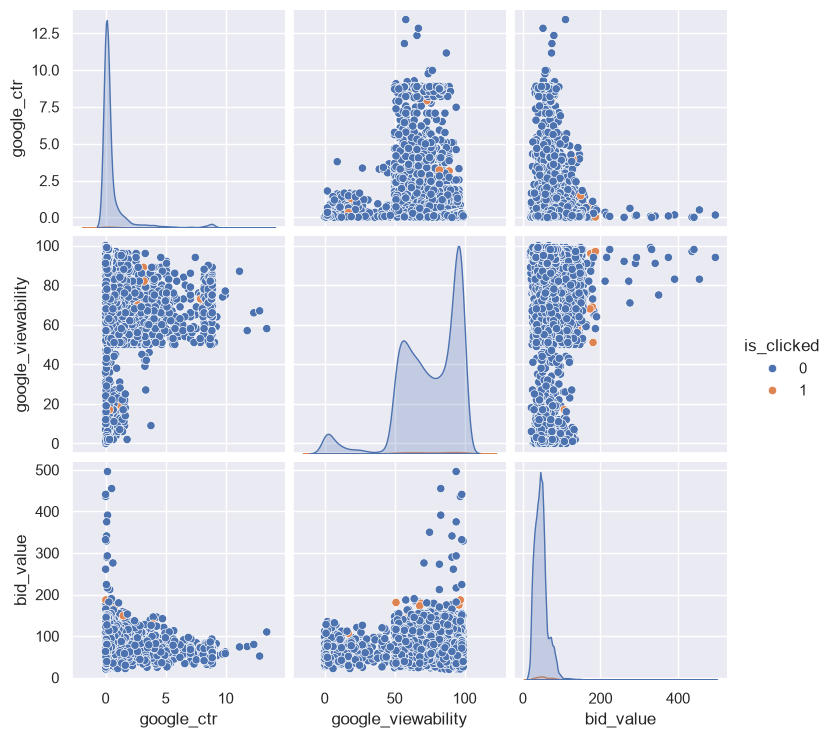

In [73]:
sns.pairplot(
    data=df,
    hue="is_clicked",
    vars=["google_ctr", "google_viewability", "bid_value"],
)
plt.show()

After taking the logarithm of the `bid_value`:

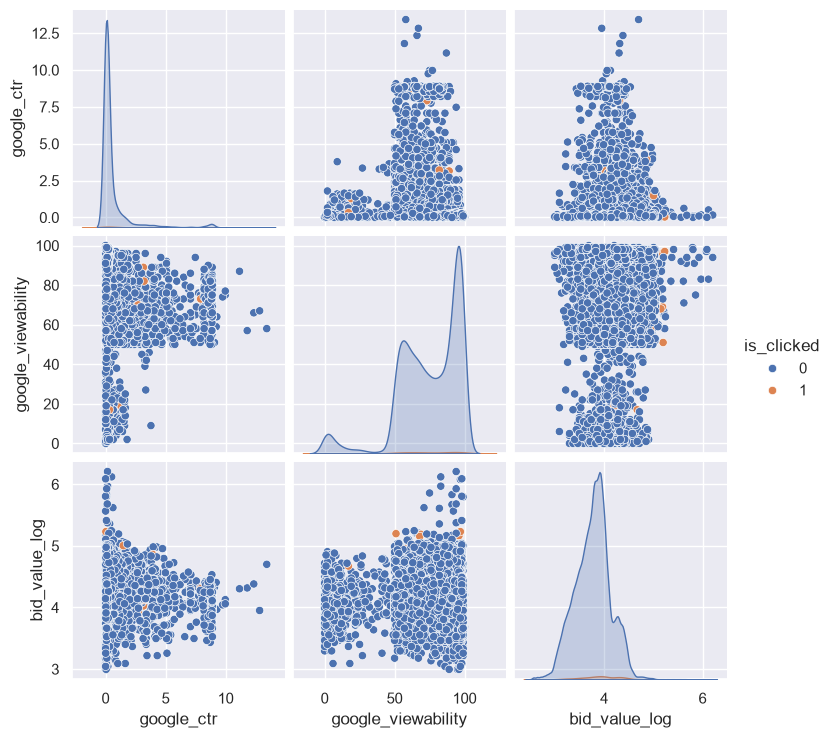

In [74]:
df["bid_value_log"] = np.log(df.bid_value)
numerical_columns = numerical_columns.append(pd.Index(["bid_value_log"]))
sns.pairplot(
    data=df,
    hue="is_clicked",
    vars=["google_ctr", "google_viewability", "bid_value_log"],
)
plt.show()

It can be seen that the variable google_viewability has a heterogeneous distribution with a clear transition at a value of 50.\
The distributions do not look Normal, so logreg is expected to not give great results.

### Encoding the rest of the categorical variables

Number of levels for each categorical variable:

In [75]:
pd.DataFrame({"nunique": df[categorical_columns].nunique(dropna=False)})

,nunique
exchange_id,5
dimension_id,6
ab_fold,4
user_agent,23850
ip,187612
device_type,5
biz,3
connection_type,10
country,28
city,2326


In [76]:
### Backing up the dataframe just in case

df_backup = df.copy()
# df = df_backup.copy()

Filling missing values for categorical variables with corresponding mode value, and for numerical values - with corresponding median.\
Splitting the data frame into train and test sets before encoding to ensure no test data leakage happens.

In [ ]:
df_train, df_test = train_test_split(df, random_state=SEED, test_size=0.2, shuffle=False)

In [78]:
df_cat_modes = df_train[categorical_columns].mode().iloc[0, :]
df_num_medians = df_train[numerical_columns].median()

df_fillna_vals = pd.concat([df_cat_modes, df_num_medians]).to_dict()

df_train_nona = df_train.fillna(df_fillna_vals)
df_test_nona = df_test.fillna(df_fillna_vals)

print(f"All NaN values have been filled: {all(df_train_nona.isna().mean() == 0) and all(df_test_nona.isna().mean() == 0)}")

All NaN values have been filled: True


For logistic regression all variables should be numeric, so creating separate dataframe with encoded categorical values.\
Variables with number of levels below 7 can be represented by dummy variables.\
The other variables can be encoded in different ways, I will encode them with target means.

In [103]:
def encode_categories(df_train: pd.DataFrame, df_test: pd.DataFrame, colnames: list[str], target_name: str, m = 5):
    df_enc_train, df_enc_test = df_train.copy(), df_test.copy()

    got_dummied = []
    target_encodings = {}
    mean_target = df_train[target_name].mean()

    for col in colnames:
        if df_enc_train[col].nunique() < 7:
            got_dummied.append(col)
            dummies_train = pd.get_dummies(df_enc_train[col], prefix=col, drop_first=True)
            dummies_test = pd.get_dummies(df_enc_test[col], prefix=col, drop_first=True)
            df_enc_train = pd.concat((df_enc_train.drop(col, axis=1), dummies_train), axis=1)
            df_enc_test = pd.concat((df_enc_test.drop(col, axis=1), dummies_test), axis=1)
        else:
            encoding_stats_bycol = df_enc_train.groupby(col).agg({"is_clicked": ["mean", "count"]}).droplevel(0, axis=1)
            n, cat_mean = encoding_stats_bycol["count"], encoding_stats_bycol["mean"]
            smoothed_means = n / (n + m) * cat_mean + m / (n + m) * mean_target
            target_encodings[col] = smoothed_means
            df_enc_train[col] = df_enc_train[col].map(smoothed_means)
            df_enc_test[col] = df_enc_test[col].map(smoothed_means).fillna(mean_target)

        
    return df_enc_train, df_enc_test, got_dummied, target_encodings

### Encoding the categorical variables
df_enc_train, df_enc_test, got_dummied, target_encodings = encode_categories(df_train, df_test, categorical_columns, "is_clicked")
df_enc_train_nona, df_enc_test_nona, _, _ = encode_categories(df_train_nona, df_test_nona, categorical_columns, "is_clicked")

display(df_enc_train.head())
display(df_enc_train_nona.head())

,ias_viewability,google_ctr,google_viewability,bid_value,user_agent,ip,connection_type,country,city,latitude,longitude,postal_code,is_clicked,url_main,url_full,hour,month,bid_value_log,exchange_id_14,exchange_id_19,exchange_id_2,exchange_id_9,dimension_id_251,dimension_id_253,dimension_id_254,dimension_id_406108,dimension_id_890689,ab_fold_b,ab_fold_u,device_type_1,device_type_2,device_type_3,device_type_4,biz_home
0,65.0,NaN,NaN,78.0,0.181086,0.181086,0.008981,0.014083,0.008178,35.69242,139.63786,0.009441,1,0.022483,0.120724,9,4,4.356709,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
1,85.0,NaN,NaN,27.0,0.108651,0.181086,0.009473,0.014083,0.038804,33.68545,135.98235,0.181086,1,0.028572,0.028572,5,4,3.295837,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False
2,NaN,NaN,NaN,90.0,0.007270,0.181086,0.013303,0.872801,0.908358,53.44000,-2.24000,0.908358,1,0.052730,0.181086,3,3,4.499810,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False
3,65.0,NaN,NaN,69.0,0.004077,0.181086,0.013303,0.014083,0.038639,35.16230,134.87315,0.108651,1,0.015901,0.181086,22,3,4.234107,True,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False
4,45.0,NaN,NaN,71.0,0.342946,0.605768,NaN,0.014083,0.044781,35.68950,139.69170,0.044781,1,0.065844,0.181086,3,3,4.262680,False,False,True,False,True,False,False,False,False,False,True,False,True,False,False,False


,ias_viewability,google_ctr,google_viewability,bid_value,user_agent,ip,connection_type,country,city,latitude,longitude,postal_code,is_clicked,url_main,url_full,hour,month,bid_value_log,exchange_id_14,exchange_id_19,exchange_id_2,exchange_id_9,dimension_id_251,dimension_id_253,dimension_id_254,dimension_id_406108,dimension_id_890689,ab_fold_b,ab_fold_u,device_type_1,device_type_2,device_type_3,device_type_4,biz_home
0,65.0,0.087,77.0,78.0,0.181086,0.181086,0.008981,0.014079,0.008178,35.69242,139.63786,0.009441,1,0.022483,0.120724,9,4,4.356709,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
1,85.0,0.087,77.0,27.0,0.108651,0.181086,0.009473,0.014079,0.038804,33.68545,135.98235,0.181086,1,0.028572,0.028572,5,4,3.295837,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False
2,65.0,0.087,77.0,90.0,0.007270,0.181086,0.019807,0.872801,0.908358,53.44000,-2.24000,0.908358,1,0.052730,0.181086,3,3,4.499810,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False
3,65.0,0.087,77.0,69.0,0.004077,0.181086,0.019807,0.014079,0.038639,35.16230,134.87315,0.108651,1,0.015901,0.181086,22,3,4.234107,True,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False
4,45.0,0.087,77.0,71.0,0.342946,0.605768,0.019807,0.014079,0.051803,35.68950,139.69170,0.052200,1,0.065844,0.181086,3,3,4.262680,False,False,True,False,True,False,False,False,False,False,True,False,True,False,False,False


# ML models training

## Logistic regression

In [104]:
X_train, X_test, Y_train, Y_test = (
    df_enc_train_nona.drop("is_clicked", axis=1),
    df_enc_test_nona.drop("is_clicked", axis=1),
    df_enc_train_nona["is_clicked"],
    df_enc_test_nona["is_clicked"],
)

In [105]:
X_train

,ias_viewability,google_ctr,google_viewability,bid_value,user_agent,ip,connection_type,country,city,latitude,longitude,postal_code,url_main,url_full,hour,month,bid_value_log,exchange_id_14,exchange_id_19,exchange_id_2,exchange_id_9,dimension_id_251,dimension_id_253,dimension_id_254,dimension_id_406108,dimension_id_890689,ab_fold_b,ab_fold_u,device_type_1,device_type_2,device_type_3,device_type_4,biz_home
0,65.0,0.087,77.0,78.0,0.181086,0.181086,0.008981,0.014079,0.008178,35.69242,139.63786,0.009441,0.022483,0.120724,9,4,4.356709,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
1,85.0,0.087,77.0,27.0,0.108651,0.181086,0.009473,0.014079,0.038804,33.68545,135.98235,0.181086,0.028572,0.028572,5,4,3.295837,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False
2,65.0,0.087,77.0,90.0,0.007270,0.181086,0.019807,0.872801,0.908358,53.44000,-2.24000,0.908358,0.052730,0.181086,3,3,4.499810,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False
3,65.0,0.087,77.0,69.0,0.004077,0.181086,0.019807,0.014079,0.038639,35.16230,134.87315,0.108651,0.015901,0.181086,22,3,4.234107,True,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False
4,45.0,0.087,77.0,71.0,0.342946,0.605768,0.019807,0.014079,0.051803,35.68950,139.69170,0.052200,0.065844,0.181086,3,3,4.262680,False,False,True,False,True,False,False,False,False,False,True,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251341,65.0,0.087,77.0,72.0,0.005065,0.014419,0.019807,0.014079,0.026345,34.67094,135.50750,0.027007,0.002704,0.014419,10,4,4.276666,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False
251342,45.0,0.087,77.0,23.0,0.005065,0.012359,0.019807,0.014079,0.008431,35.74211,139.79700,0.002110,0.007530,0.010814,14,4,3.135494,False,False,True,False,False,False,False,True,False,False,True,False,False,False,False,True
251343,20.0,0.087,77.0,49.0,0.005065,0.012359,0.017895,0.014079,0.010359,35.53062,139.63477,0.012208,0.052007,0.012359,23,4,3.891820,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False
251344,85.0,0.087,77.0,78.0,0.005065,0.014419,0.019807,0.014079,0.014419,35.79783,139.96733,0.014419,0.006655,0.014419,1,4,4.356709,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,True


There is a large class imbalance in the data:

In [106]:
np.round(np.mean(Y_train == 0), 4).item()

0.9827

This means that accuracy metric will be inappropriate for comparing models.\
The precision and recall metrics will suit better.

### Selecting features with logistic regression with $l_1$ penalty

Using basic optuna api, though `optuna.integration.OptunaSearchCV` is simpler and will be used for later sklearn models.

In [107]:
class LR_feature_selector_objective():
    def __init__(self, base_model: Pipeline, X: pd.DataFrame, Y: pd.DataFrame, **kwargs):
        self.model: Pipeline = base_model
        self.X = X
        self.Y = Y
        self.cv_params = kwargs
    
    def __call__(self, trial: optuna.Trial):
        C = trial.suggest_float("C", 1e-6, 1e6, log=True)

        self.model.set_params(LR__C=C)

        score = cross_val_score(self.model, self.X, self.Y, **self.cv_params).mean()
        return score

feature_selector = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "LR",
            LogisticRegression(
                l1_ratio=1,
                solver="liblinear",
            ),
        ),
    ]
)

LR_fs_objective = LR_feature_selector_objective(feature_selector, X_train, Y_train, scoring=make_scorer(f1_score))
LR_fs_study = optuna.create_study(direction="maximize")

[I 2026-11-06 14:03:05,163] A new study created in memory with name: no-name-4bd01c9a-bb53-41d9-b1e8-b07c84165f7c


In [108]:
LR_fs_study.optimize(LR_fs_objective, n_trials=10, timeout=600, n_jobs=-1)

[I 2026-11-06 14:04:43,576] Trial 0 finished with value: 0.9255284937407596 and parameters: {'C': 184884.42622102876}. Best is trial 0 with value: 0.9255284937407596.
[I 2026-11-06 14:04:44,850] Trial 4 finished with value: 0.9255284937407596 and parameters: {'C': 0.06573755929469403}. Best is trial 0 with value: 0.9255284937407596.
[I 2026-11-06 14:04:46,739] Trial 7 finished with value: 0.9255284937407596 and parameters: {'C': 1.295909878034142}. Best is trial 0 with value: 0.9255284937407596.
[I 2026-11-06 14:04:47,249] Trial 6 finished with value: 0.9255284937407596 and parameters: {'C': 19.32252121031609}. Best is trial 0 with value: 0.9255284937407596.
[I 2026-11-06 14:04:48,465] Trial 3 finished with value: 0.9255284937407596 and parameters: {'C': 12685.456189347391}. Best is trial 0 with value: 0.9255284937407596.
[I 2026-11-06 14:04:51,978] Trial 1 finished with value: 0.9255284937407596 and parameters: {'C': 38.89492745656936}. Best is trial 0 with value: 0.9255284937407596.


In [109]:
feature_selector.set_params(LR__C=LR_fs_study.best_params["C"])
feature_selector.fit(X_train, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('LR', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](33,)","['ias_viewability','google_ctr','google_viewability',...,'device_type_3', 'device_type_4','biz_home']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,33
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [110]:
pd.DataFrame(
    {"coef": feature_selector["LR"].coef_[0, :]}, index=X_train.columns
).query("abs(coef)<1e-8")

,coef


Dropping features for which coefficients got cancelled (if any)

In [111]:
X_train = X_train.drop(X_train.columns[abs(feature_selector["LR"].coef_[0, :]) < 1e-8], axis=1)
X_test = X_test.drop(X_test.columns[abs(feature_selector["LR"].coef_[0, :]) < 1e-8], axis=1)

### Training logistic regression model with elastic net penalty

In [112]:
LR_pipe = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "LR",
            LogisticRegression(solver="saga"),
        ),
    ]
)

LR_param_distributions = {
    "LR__C": optuna.distributions.FloatDistribution(1e-6, 1e6, log=True),
    "LR__l1_ratio": optuna.distributions.FloatDistribution(0, 1),
    "LR__class_weight": optuna.distributions.CategoricalDistribution([None, "balanced"])
}

LR_search = optuna_integration.OptunaSearchCV(
    LR_pipe, LR_param_distributions, n_trials=20, timeout=600, verbose=1, n_jobs=-1, random_state=SEED, scoring=make_scorer(f1_score)
)

/tmp/ipykernel_65890/1716503894.py:17: ExperimentalWarning: OptunaSearchCV is experimental (supported from v0.17.0). The interface can change in the future.
  LR_search = optuna_integration.OptunaSearchCV(


In [113]:
LR_search.fit(X_train, Y_train)

[I 2026-11-06 14:05:14,065] A new study created in memory with name: no-name-9a49dccc-a22d-4940-8ce3-8c216ad866dd


/home/nikita/Projects/CTR_prediction/.venv/lib/python3.14/site-packages/optuna_integration/sklearn/sklearn.py:275: FutureWarning: `optuna.terminator` module has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0.
  report_cross_validation_scores(trial, scores_list)
[I 2026-11-06 14:05:35,152] Trial 5 finished with value: 0.9086733743014948 and parameters: {'LR__C': 5.501826797583523e-06, 'LR__l1_ratio': 0.01563774484541436, 'LR__class_weight': 'balanced'}. Best is trial 5 with value: 0.9086733743014948.
/home/nikita/Projects/CTR_prediction/.venv/lib/python3.14/site-packages/optuna_integration/sklearn/sklearn.py:275: FutureWarning: `optuna.terminator` module has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0.
  report_cross_validation_scores(trial, scores_list)
[I 2026-11-06 14:05:41,980] Trial 4 finished with value: 0.9139221875755933 and

,estimator,Pipeline(step...ver='saga'))])
,param_distributions,"{'LR__C': FloatDistribu...06, step=None), 'LR__class_weight': CategoricalDi..., 'balanced')), 'LR__l1_ratio': FloatDistribu....0, step=None)}"
,n_jobs,-1
,n_trials,20
,random_state,1
,scoring,make_scorer(f...hod='predict')
,timeout,600
,verbose,1
,cv,None
,enable_pruning,False
,error_score,nan


In [114]:
LR_pipe.set_params(**LR_search.best_estimator_.get_params())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('LR', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](33,)","['ias_viewability','google_ctr','google_viewability',...,'device_type_3', 'device_type_4','biz_home']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,33
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Metrics of the model:

In [115]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

LR_predictions = LR_pipe.predict(X_test)
LR_predictions_proba = LR_pipe.predict_proba(X_test)

print(f"Precision = {np.round(precision_score(LR_predictions, Y_test), 4)}")
print(f"Recall    = {np.round(recall_score(LR_predictions, Y_test), 4)}")
print(f"F score   = {np.round(f1_score(LR_predictions, Y_test), 4)}")

Precision = 0.478
Recall    = 0.8779
F score   = 0.619


In [116]:
pd.DataFrame(LR_predictions_proba).rename(columns={0: "F", 1: "T"}).query(
    "F > 1 or F < 0 or T > 1 or T < 0"
)

,F,T


### ROC-curve:

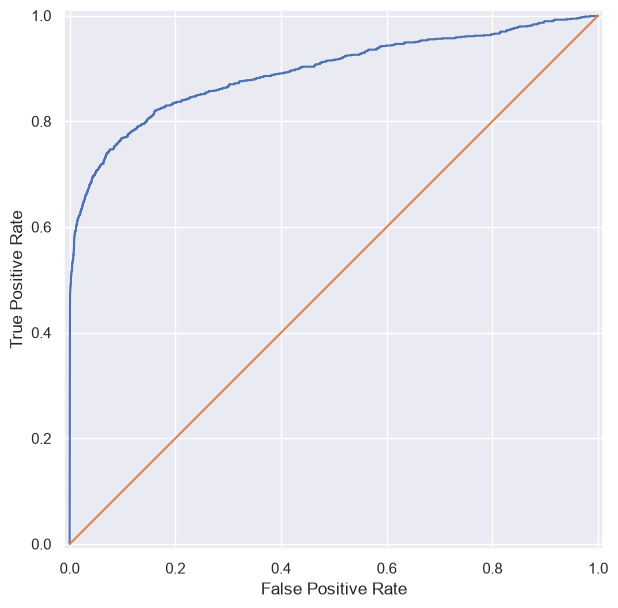

In [117]:
fpr, tpr, thresholds = roc_curve(Y_test, LR_predictions_proba[:, 1])
RocCurveDisplay(fpr=fpr, tpr=tpr).plot()
plt.plot([0, 1], [0, 1])
plt.show()

The ROC-curve is above the diagonal line, which means that it is better than a
no-skill classifier.

In [118]:
print("AUC: ", np.round(auc(fpr, tpr), 4))

AUC:  0.8932


### PR-curve:

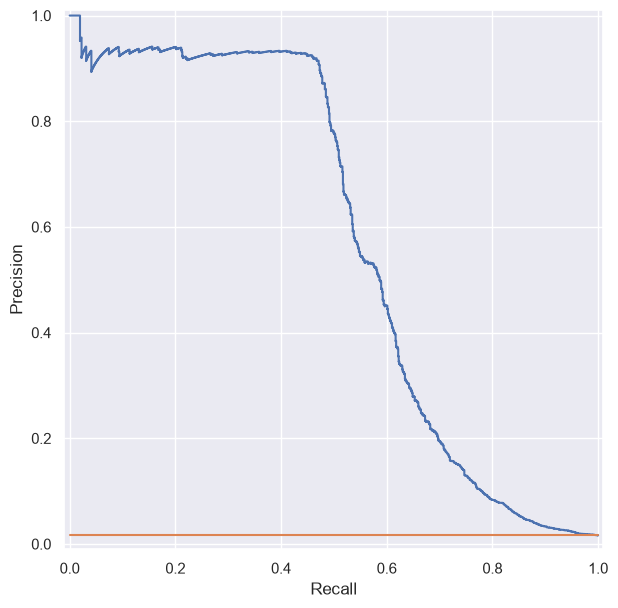

In [119]:
precision, recall, thresholds = precision_recall_curve(
    Y_test, LR_predictions_proba[:, 1]
)

PrecisionRecallDisplay(precision=precision, recall=recall).plot()
ratio = Y_train.mean()
plt.plot([0, 1], [ratio, ratio])
plt.show()

Horizontal line corresponds to the PR-curve of a no-skill classifier.

In [120]:
print("AUC: ", np.round(auc(recall, precision), 4))

AUC:  0.573


In [121]:
f_scores = 2 * precision * recall / (precision + recall)
print("Best F-score: ", np.round(np.max(f_scores), 4))
print("Threshold for the best F-score: ", np.round(thresholds[np.argmax(f_scores)], 4))
print("Corresponding Precision: ", np.round(precision[np.argmax(f_scores)], 4))
print("Corresponding Recall: ", np.round(recall[np.argmax(f_scores)], 4))

Best F-score:  0.6219
Threshold for the best F-score:  0.6481
Corresponding Precision:  0.9146
Corresponding Recall:  0.4712


In [122]:
# Saving training data for later benchmarking

LR_bench_data = X_test

## Decision Tree classifier

Since decision trees can handle missing and non-numeric values themselves, I will not fill them.

In [123]:
X_train, X_test, Y_train, Y_test = df_enc_train.drop("is_clicked", axis=1), df_enc_test.drop("is_clicked", axis=1), df_enc_train["is_clicked"], df_enc_test["is_clicked"]

In [124]:
Tree_clf = Pipeline([("scaler", StandardScaler()), ("Tree", DecisionTreeClassifier(criterion="gini", random_state=SEED))])

tree_param_distributions = {
    "Tree__max_depth": optuna.distributions.IntDistribution(2, 64, log=True),
    "Tree__class_weight": optuna.distributions.CategoricalDistribution([None, "balanced"]),
    "Tree__min_samples_leaf": optuna.distributions.IntDistribution(1, 512, log=True),
    "Tree__splitter": optuna.distributions.CategoricalDistribution(["best", "random"]),
}

Tree_search = optuna_integration.OptunaSearchCV(
    Tree_clf, tree_param_distributions, n_trials=20, timeout=600, verbose=1, n_jobs=-1, random_state=SEED, scoring=make_scorer(f1_score)
)

/tmp/ipykernel_65890/3364273378.py:10: ExperimentalWarning: OptunaSearchCV is experimental (supported from v0.17.0). The interface can change in the future.
  Tree_search = optuna_integration.OptunaSearchCV(


In [125]:
Tree_search.fit(X_train, Y_train)

[I 2026-11-06 14:10:49,876] A new study created in memory with name: no-name-11325969-8a77-441d-9626-47457b9251b0
/home/nikita/Projects/CTR_prediction/.venv/lib/python3.14/site-packages/optuna_integration/sklearn/sklearn.py:275: FutureWarning: `optuna.terminator` module has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0.
  report_cross_validation_scores(trial, scores_list)
[I 2026-11-06 14:11:05,167] Trial 1 finished with value: 0.8313750260780159 and parameters: {'Tree__max_depth': 2, 'Tree__class_weight': 'balanced', 'Tree__min_samples_leaf': 2, 'Tree__splitter': 'random'}. Best is trial 1 with value: 0.8313750260780159.
/home/nikita/Projects/CTR_prediction/.venv/lib/python3.14/site-packages/optuna_integration/sklearn/sklearn.py:275: FutureWarning: `optuna.terminator` module has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0.
  repo

,estimator,Pipeline(step...om_state=1))])
,param_distributions,"{'Tree__class_weight': CategoricalDi..., 'balanced')), 'Tree__max_depth': IntDistributi...low=2, step=1), 'Tree__min_samples_leaf': IntDistributi...low=1, step=1), 'Tree__splitter': CategoricalDi...t', 'random'))}"
,n_jobs,-1
,n_trials,20
,random_state,1
,scoring,make_scorer(f...hod='predict')
,timeout,600
,verbose,1
,cv,None
,enable_pruning,False
,error_score,nan


In [126]:
Tree_clf.set_params(**Tree_search.best_estimator_.get_params())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('Tree', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](33,)","['ias_viewability','google_ctr','google_viewability',...,'device_type_3', 'device_type_4','biz_home']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,33
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


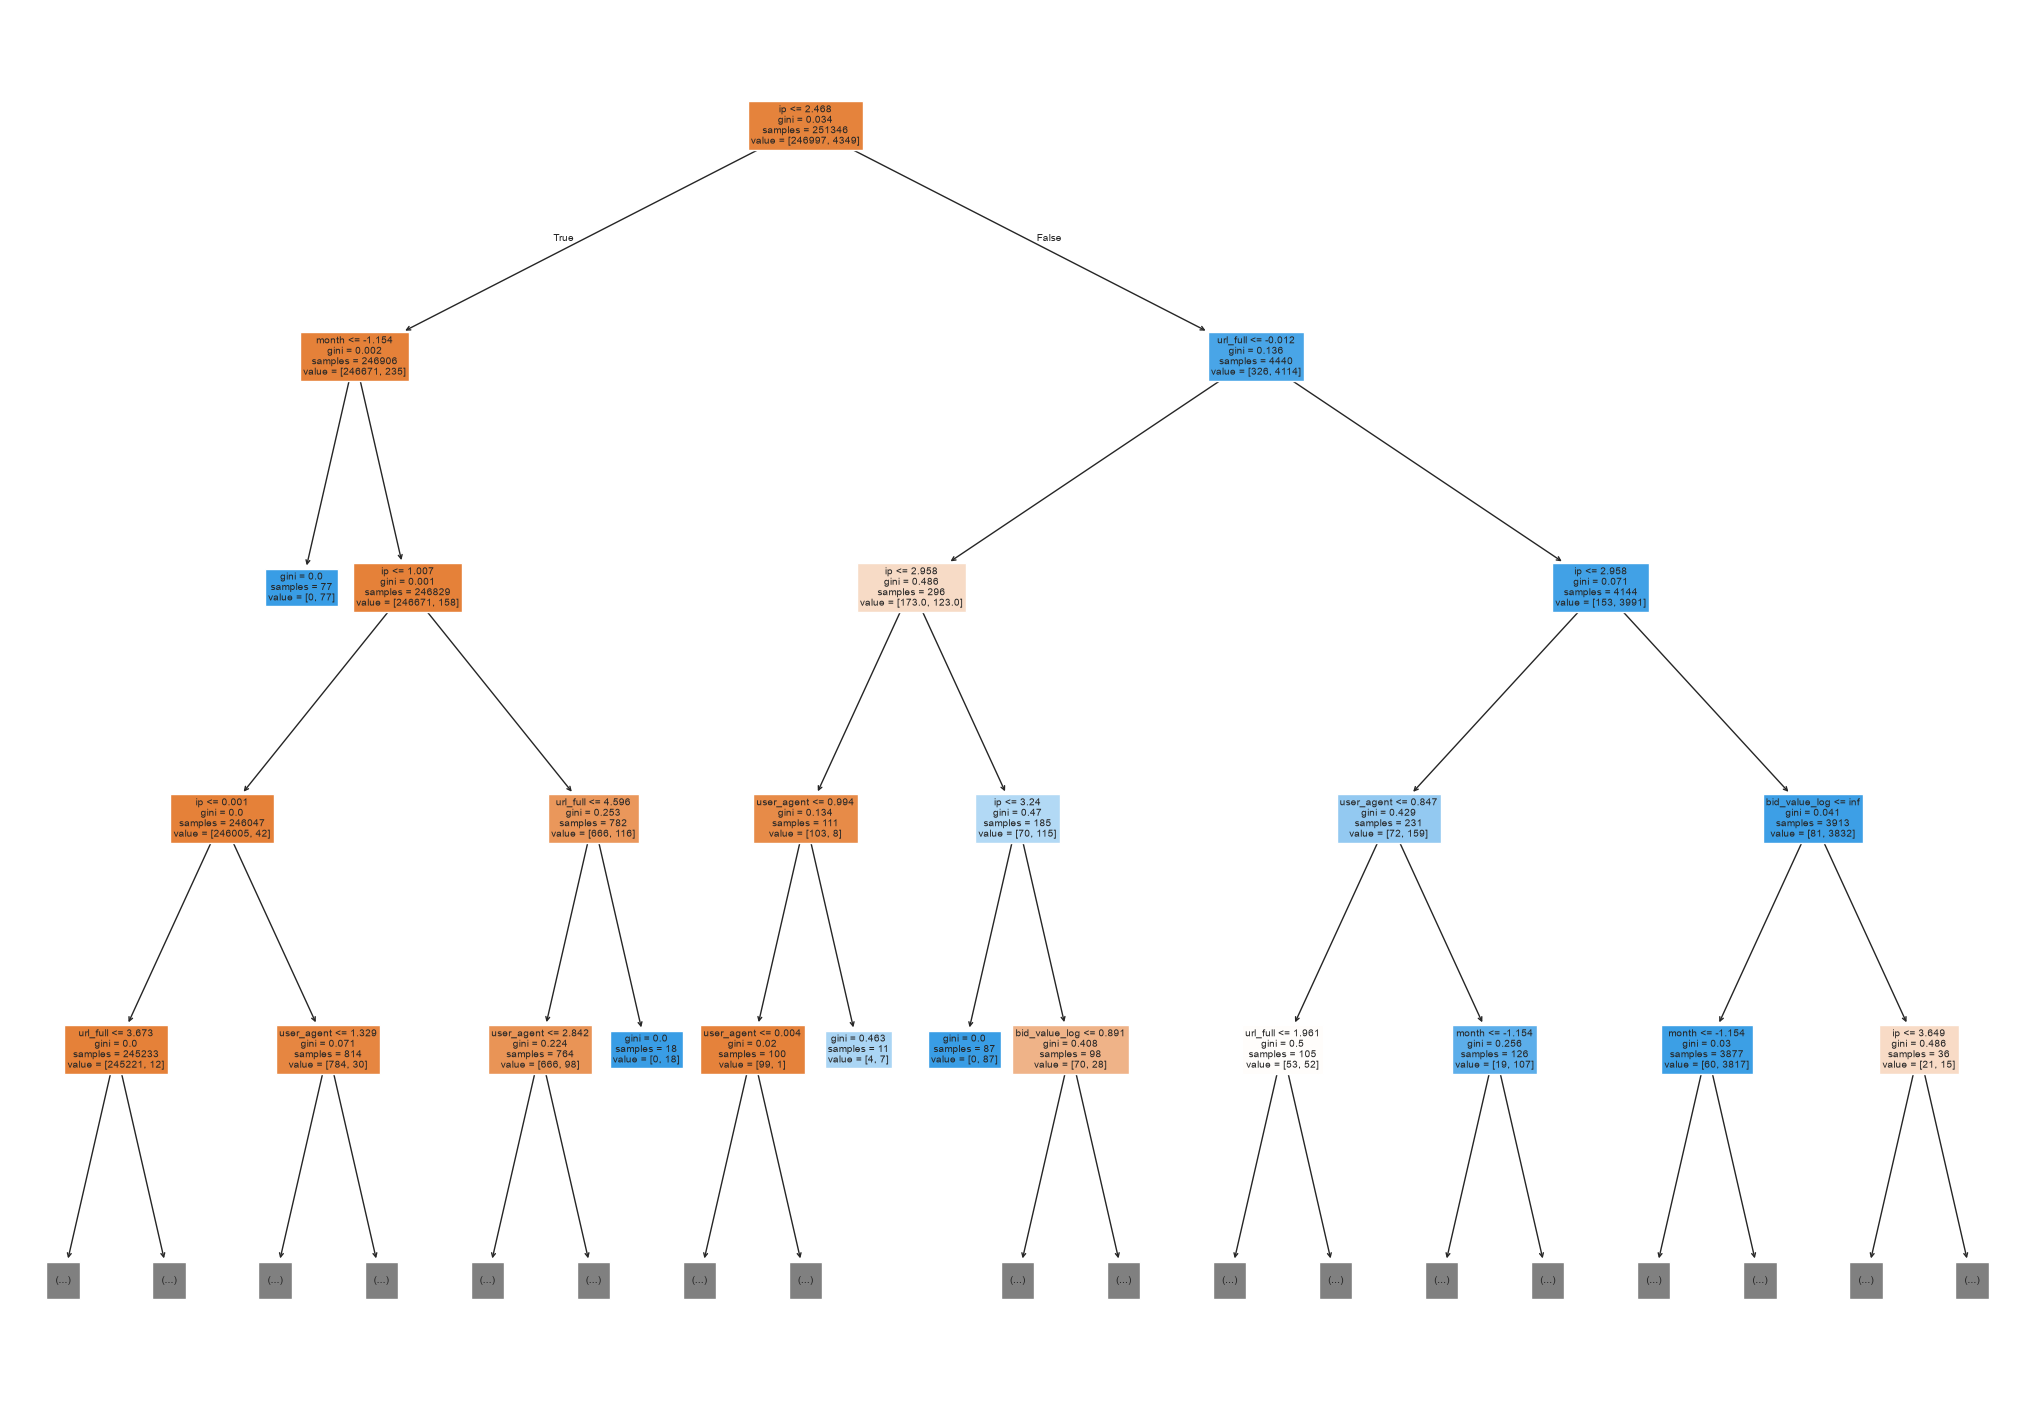

In [168]:
sns.set(rc={"figure.figsize": (26, 18)})
plot_tree(
    Tree_clf["Tree"],
    filled=True,
    max_depth=4,
    feature_names=X_train.columns,
)
plt.show()

Most valuable features for the tree seem to be historical information about ip and url

In [128]:
Tree_predictions = Tree_clf.predict(X_test)
Tree_predictions_proba = Tree_clf.predict_proba(X_test)

print("Precision = ", np.round(precision_score(Tree_predictions, Y_test), 4))
print("Recall = ", np.round(recall_score(Tree_predictions, Y_test), 4))
print("F score = ", np.round(f1_score(Tree_predictions, Y_test), 4))

Precision =  0.6774
Recall =  0.9094
F score =  0.7765


### ROC-curve

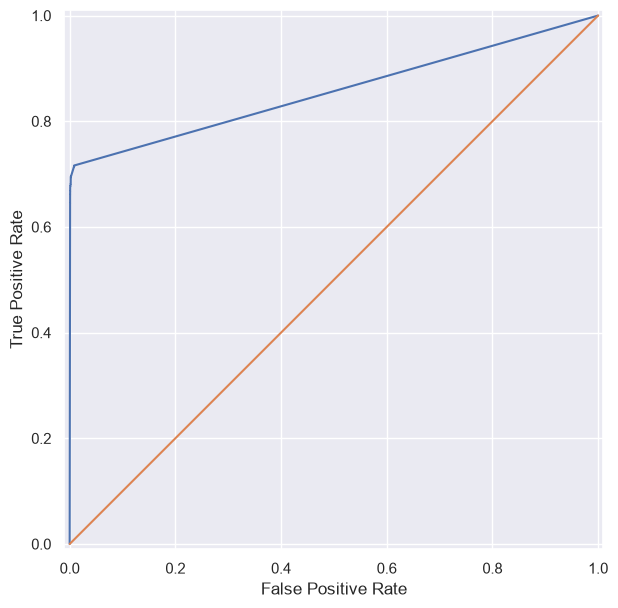

In [129]:
sns.set(rc={"figure.figsize": (13, 7)})

fpr, tpr, thresholds = roc_curve(Y_test, Tree_predictions_proba[:, 1])
RocCurveDisplay(fpr=fpr, tpr=tpr).plot()
plt.plot([0, 1], [0, 1])
plt.show()

In [130]:
print("AUC: ", np.round(auc(fpr, tpr), 4))

AUC:  0.8565


### PR-curve

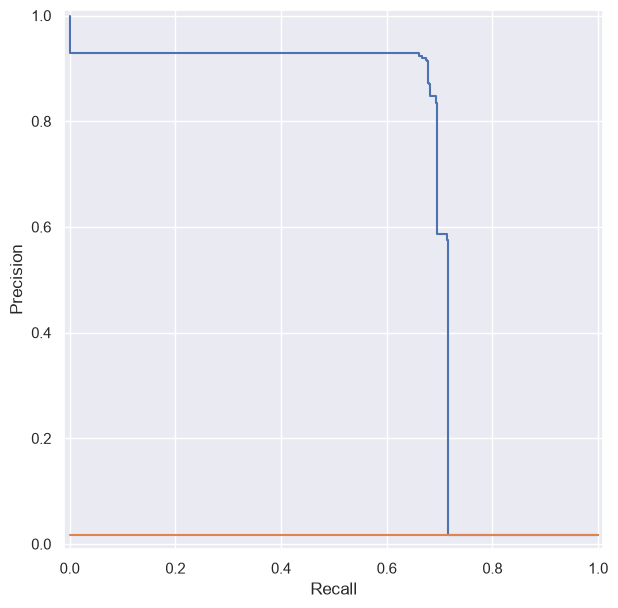

In [131]:
precision, recall, thresholds = precision_recall_curve(
    Y_test, Tree_predictions_proba[:, 1]
)

PrecisionRecallDisplay(precision=precision, recall=recall).plot()
ratio = Y_train.mean()
plt.plot([0, 1], [ratio, ratio]);

In [132]:
print("AUC: ", np.round(auc(recall, precision), 4))

AUC:  0.7633


In [133]:
f_scores = 2 * precision * recall / (precision + recall)
print("Best F-score: ", np.round(np.max(f_scores), 4))
print("Threshold for the best F-score: ", np.round(thresholds[np.argmax(f_scores)], 4))
print("Corresponding Precision: ", np.round(precision[np.argmax(f_scores)], 4))
print("Corresponding Recall: ", np.round(recall[np.argmax(f_scores)], 4))

Best F-score:  0.7783
Threshold for the best F-score:  0.619
Corresponding Precision:  0.92
Corresponding Recall:  0.6745


In [134]:
# Saving training data for later benchmarking

Tree_bench_data = X_test

### Random Forest Classifier

In [135]:
RF_clf = Pipeline([("scaler", StandardScaler()), ("RF", RandomForestClassifier(criterion="gini", random_state=SEED))])

RF_param_distributions = {
    "RF__n_estimators": optuna.distributions.IntDistribution(1, 128),
    "RF__max_depth": optuna.distributions.IntDistribution(2, 32, log=True),
    "RF__class_weight": optuna.distributions.CategoricalDistribution([None, "balanced"]),
    "RF__min_samples_leaf": optuna.distributions.IntDistribution(1, 512, log=True),
    "RF__max_samples": optuna.distributions.FloatDistribution(0.3, 0.7)
}

RF_search = optuna_integration.OptunaSearchCV(
    RF_clf, RF_param_distributions, n_trials=20, timeout=600, verbose=1, n_jobs=-1, random_state=SEED, scoring=make_scorer(f1_score)
)

/tmp/ipykernel_65890/3475585465.py:11: ExperimentalWarning: OptunaSearchCV is experimental (supported from v0.17.0). The interface can change in the future.
  RF_search = optuna_integration.OptunaSearchCV(


In [136]:
RF_search.fit(X_train, Y_train)

[I 2026-11-06 14:11:42,586] A new study created in memory with name: no-name-0f34208b-c88c-42f3-9d69-60484becdcaf
/home/nikita/Projects/CTR_prediction/.venv/lib/python3.14/site-packages/optuna_integration/sklearn/sklearn.py:275: FutureWarning: `optuna.terminator` module has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0.
  report_cross_validation_scores(trial, scores_list)
[I 2026-11-06 14:11:55,686] Trial 2 finished with value: 0.9379246946802553 and parameters: {'RF__n_estimators': 3, 'RF__max_depth': 15, 'RF__class_weight': None, 'RF__min_samples_leaf': 491, 'RF__max_samples': 0.4166080015785605}. Best is trial 2 with value: 0.9379246946802553.
/home/nikita/Projects/CTR_prediction/.venv/lib/python3.14/site-packages/optuna_integration/sklearn/sklearn.py:275: FutureWarning: `optuna.terminator` module has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/re

,estimator,Pipeline(step...om_state=1))])
,param_distributions,"{'RF__class_weight': CategoricalDi..., 'balanced')), 'RF__max_depth': IntDistributi...low=2, step=1), 'RF__max_samples': FloatDistribu....3, step=None), 'RF__min_samples_leaf': IntDistributi...low=1, step=1), ...}"
,n_jobs,-1
,n_trials,20
,random_state,1
,scoring,make_scorer(f...hod='predict')
,timeout,600
,verbose,1
,cv,None
,enable_pruning,False
,error_score,nan


In [137]:
RF_clf.set_params(**RF_search.best_estimator_.get_params())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('RF', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](33,)","['ias_viewability','google_ctr','google_viewability',...,'device_type_3', 'device_type_4','biz_home']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,33
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [138]:
RF_predictions = RF_clf.predict(X_test)
RF_predictions_proba = RF_clf.predict_proba(X_test)

print("Precision = ", np.round(precision_score(RF_predictions, Y_test), 4))
print("Recall = ", np.round(recall_score(RF_predictions, Y_test), 4))
print("F score = ", np.round(f1_score(RF_predictions, Y_test), 4))

fpr, tpr, thresholds = roc_curve(Y_test, RF_predictions_proba[:, 1])
print("ROC AUC: ", np.round(auc(fpr, tpr), 4))

precision, recall, thresholds = precision_recall_curve(
    Y_test, RF_predictions_proba[:, 1]
)
print("PR AUC: ", np.round(auc(recall, precision), 4))

f_scores = 2 * precision * recall / (precision + recall)
print("Best F-score: ", np.round(np.max(f_scores), 4))
print("Threshold for the best F-score: ", np.round(thresholds[np.argmax(f_scores)], 4))
print("Corresponding Precision: ", np.round(precision[np.argmax(f_scores)], 4))
print("Corresponding Recall: ", np.round(recall[np.argmax(f_scores)], 4))

Precision =  0.6979
Recall =  0.9225
F score =  0.7947
ROC AUC:  0.9389
PR AUC:  0.798
Best F-score:  0.8168
Threshold for the best F-score:  0.1883
Corresponding Precision:  0.8596
Corresponding Recall:  0.7781


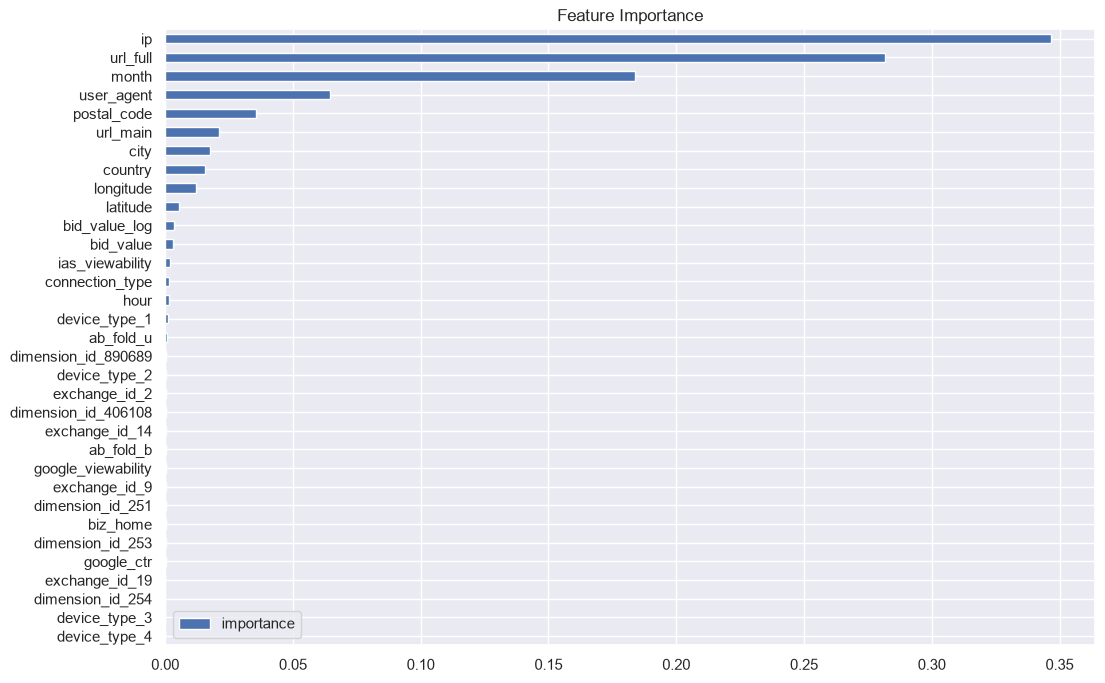

In [139]:
pd.DataFrame(
    {
        "importance": RF_clf["RF"].feature_importances_,
    },
    index=list(X_train),
).sort_values("importance", ascending=True).plot(kind="barh", figsize=(12, 8), title="Feature Importance")
plt.show()

For random forest historical data about ip and url are the most important, which is the same as for individual trees.

In [140]:
# Saving training data for later benchmarking

RF_bench_data = X_test

# Boosting on trees with XGBoost

In [141]:
dtrain = xgb.DMatrix(X_train, label=Y_train)

def xgb_objective(trial):
    param = {
        "verbosity": 1,
        "device": "cuda",
        "objective": "binary:logistic",
        "eval_metric": "auc",
        "booster": "gbtree",
        "lambda": trial.suggest_float("lambda", 1e-8, 1.0, log=True),
        "alpha": trial.suggest_float("alpha", 1e-8, 1.0, log=True),
        "max_depth": trial.suggest_int("max_depth", 1, 10),
        "eta": trial.suggest_float("eta", 1e-8, 1.0, log=True),
        "gamma": trial.suggest_float("gamma", 1e-8, 1.0, log=True),
        "grow_policy": trial.suggest_categorical("grow_policy", ["depthwise", "lossguide"])
    }

    pruning_callback = optuna.integration.XGBoostPruningCallback(trial, "test-auc")
    history = xgb.cv(param, dtrain, num_boost_round=80, early_stopping_rounds=10, callbacks=[pruning_callback])

    mean_auc = history["test-auc-mean"].values[-1]
    return mean_auc

pruner = optuna.pruners.MedianPruner(n_warmup_steps=5)
xgb_study = optuna.create_study(pruner=pruner, direction="maximize")
xgb_study.optimize(xgb_objective, n_trials=20)

[I 2026-11-06 14:15:44,348] A new study created in memory with name: no-name-c3caa7ff-fa39-4b53-983d-e77303279c13
/usr/lib/python3.14/importlib/__init__.py:88: FutureWarning: `optuna.integration.xgboost` has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0. Use `optuna_integration.xgboost` instead.
  return _bootstrap._gcd_import(name[level:], package, level)
[I 2026-11-06 14:15:45,605] Trial 0 finished with value: 0.9987201258132034 and parameters: {'lambda': 0.0004549008014678393, 'alpha': 0.3074700125288217, 'max_depth': 4, 'eta': 0.22523217529883852, 'gamma': 0.00200208520676406, 'grow_policy': 'depthwise'}. Best is trial 0 with value: 0.9987201258132034.
[I 2026-11-06 14:15:46,529] Trial 1 finished with value: 0.9967841464472494 and parameters: {'lambda': 3.4219560853597767e-06, 'alpha': 0.0002589055976107048, 'max_depth': 6, 'eta': 5.690502043398311e-06, 'gamma': 0.00014736767111875635, 'grow_policy': 'los

In [142]:
xgb_params = {
    "verbosity": 1,
    "device": "cuda",
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "booster": "gbtree"}
xgb_params.update(xgb_study.best_params)

XGB_clf = xgb.train(xgb_params, dtrain, num_boost_round=200)

In [166]:
dtest = xgb.DMatrix(X_test, label=Y_test)
XGB_predictions_proba = XGB_clf.predict(dtest)

fpr, tpr, thresholds = roc_curve(Y_test, XGB_predictions_proba)
print("ROC AUC: ", np.round(auc(fpr, tpr), 4))

precision, recall, thresholds = precision_recall_curve(
    Y_test, XGB_predictions_proba
)
print("PR AUC: ", np.round(auc(recall, precision), 4))

f_scores = 2 * precision * recall / (precision + recall)
best_threshold = thresholds[np.argmax(f_scores)]
print("Best F-score: ", np.round(np.max(f_scores), 4))
print("Threshold for the best F-score: ", np.round(best_threshold, 4))
print("Corresponding Precision: ", np.round(precision[np.argmax(f_scores)], 4))
print("Corresponding Recall: ", np.round(recall[np.argmax(f_scores)], 4))

XGB_predictions = np.where(XGB_predictions_proba > best_threshold, 1, 0)

print("Precision = ", np.round(precision_score(XGB_predictions, Y_test), 4))
print("Recall = ", np.round(recall_score(XGB_predictions, Y_test), 4))

ROC AUC:  0.9371
PR AUC:  0.7731
Best F-score:  0.7862
Threshold for the best F-score:  0.3385
Corresponding Precision:  0.857
Corresponding Recall:  0.7263
Precision =  0.7253
Recall =  0.8568


So far boosting and forest provide the best comparable results.

Feature importance:

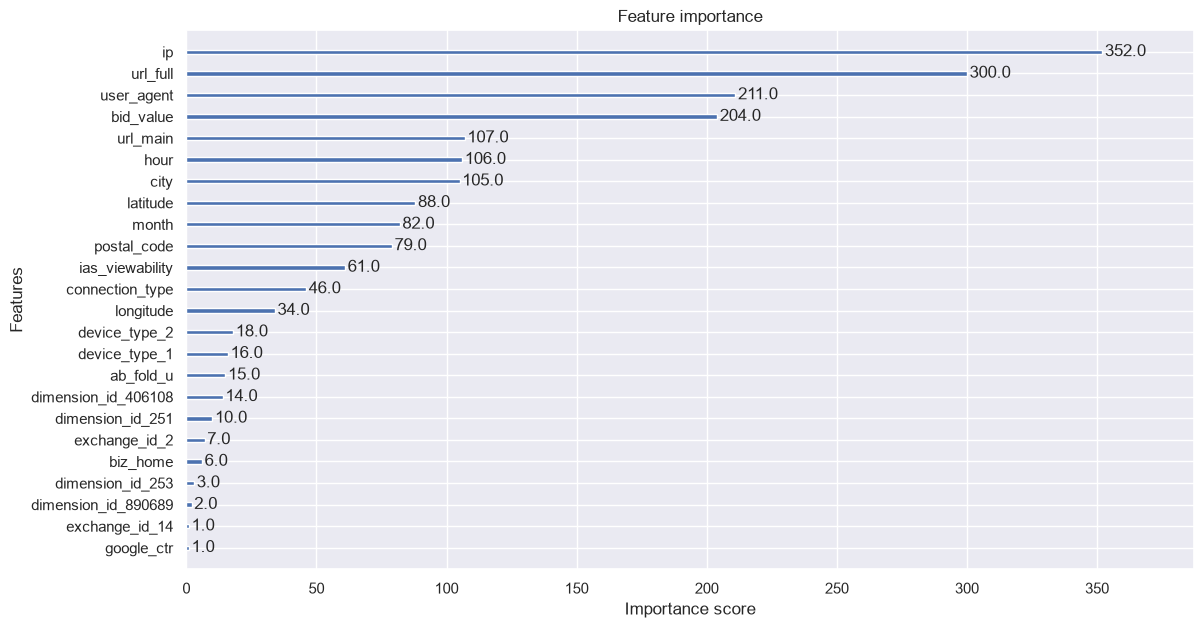

In [144]:
xgb.plot_importance(XGB_clf)
plt.show()

As with single tree and random forest, the most important features for boosting are historical data about ip and url.

In [145]:
# Saving training data for later benchmarking

XGB_bench_data = dtest

### Prediction time benchmark

Average times to predict a target value for each model (assuming preprocessed data):

### Logistic Regression:

In [146]:
print(f"Rows: {LR_bench_data.shape[0]}")

Rows: 62837


In [163]:
%%timeit

LR_pipe.predict_proba(LR_bench_data)

95.1 ms ± 3.26 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


### Decision Tree:

In [148]:
print(f"Rows: {Tree_bench_data.shape[0]}")

Rows: 62837


In [164]:
%%timeit

Tree_clf.predict_proba(Tree_bench_data)

85.7 ms ± 2.24 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


### Random Forest:

In [150]:
print(f"Rows: {RF_bench_data.shape[0]}")

Rows: 62837


In [165]:
%%timeit

RF_clf.predict_proba(RF_bench_data)

186 ms ± 14.3 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


### Boosting:

In [158]:
print(f"Rows: {XGB_bench_data.get_data().shape[0]}")

Rows: 62837


In [173]:
%%timeit

XGB_clf.predict(xgb.DMatrix(X_test))

37.2 ms ± 4.5 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


Boosting has by far the fastest inference time (even including using `DMatrix` on raw `DataFrame`) and metrics comparable with random forest,\
so I propose this model family for production.